# 03 — Entraînement : Pipeline Spark ML

Uniquement sur `train.parquet` :
1. Poids de classe (pour `weightCol`)
2. Validation interne : 80 % pour entraîner, 20 % pour valider
3. Pipeline : Transformers + Estimators
4. Comparaison LR / Random Forest / GBT, avec et sans les soldes
5. Réglage des hyperparamètres avec `CrossValidator`
6. Choix du seuil de décision sur la validation
7. Sauvegarde du modèle et du seuil

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = (SparkSession.builder
         .appName("fraude-03-entrainement")
         .master("spark://spark-master:7077")
         .config("spark.driver.host", "spark-master")
         .config("spark.driver.memory", "2g")
         .config("spark.executor.memory", "2g")
         .config("spark.sql.shuffle.partitions", "18")
         .config("spark.sql.session.timeZone", "UTC")
         .config("spark.eventLog.enabled", "true")
         .config("spark.eventLog.dir", "file:///tmp/spark-events")
         .getOrCreate())

DATA = "/opt/spark-data"
spark

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/22 00:35:50 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [2]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import Imputer, SQLTransformer, StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier, GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder
from pyspark.ml.functions import vector_to_array
import pandas as pd
import matplotlib.pyplot as plt

train = spark.read.parquet(DATA + "/ml/train.parquet")

## 1. Poids de classe

Les fraudes sont très rares : on donne à chaque fraude un poids plus fort.
Formule « balanced » : `poids = total / (2 × effectif de la classe)`.

In [3]:
nb_total = train.count()
nb_fraudes = train.filter("label = 1").count()
nb_normales = nb_total - nb_fraudes

poids_fraude = nb_total / (2 * nb_fraudes)
poids_normale = nb_total / (2 * nb_normales)
print("poids fraude :", round(poids_fraude, 2), "| poids normale :", round(poids_normale, 4))

train = train.withColumn("weight", F.when(F.col("label") == 1, poids_fraude).otherwise(poids_normale))

poids fraude : 169.31 | poids normale : 0.5015


Une fraude compte environ 338 fois plus qu'une transaction normale (169,31 / 0,5015). Sans ces poids, le modèle pourrait ignorer les fraudes tout en ayant une très bonne accuracy.

## 2. Validation interne (80 / 20 du jeu d'entraînement)

In [4]:
train_fit, validation = train.randomSplit([0.8, 0.2], seed=42)
train_fit.cache()
validation.cache()

print("train_fit :", train_fit.count(), "| validation :", validation.count())

[Stage 11:>                                                         (0 + 9) / 9]

train_fit : 1754336 | validation : 438278


1 754 336 lignes pour entraîner et 438 278 pour valider. Le jeu de test n'est pas utilisé ici.

## 3. Le Pipeline

| Étage | Type | Rôle |
|---|---|---|
| `Imputer` | Estimator | remplace les montants et soldes manquants par la médiane (calculée sur l'entraînement) |
| `SQLTransformer` | Transformer | crée `hour`, `logAmount`, `errorBalanceOrig`, `errorBalanceDest` |
| `StringIndexer` | Estimator | `type` → `typeIndex` |
| `OneHotEncoder` | Estimator | `typeIndex` → `typeVec` |
| `VectorAssembler` | Transformer | rassemble les features dans **une** colonne vecteur (obligatoire pour Spark ML) |
| `StandardScaler` | Estimator | met les features à la même échelle |
| Modèle | Estimator | LR / RF / GBT, avec `weightCol="weight"` |

In [5]:
# médiane à la place des valeurs manquantes (montant et soldes)
colonnes_numeriques = ["amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]
imputation = Imputer(inputCols=colonnes_numeriques, outputCols=colonnes_numeriques, strategy="median")

# heure, log du montant et écarts entre soldes attendus et soldes réels
creation_features = SQLTransformer(statement="""
    SELECT *,
           CAST(HOUR(transaction_time) AS DOUBLE) AS hour,  
           LOG1P(amount)                            AS logAmount,
           newbalanceOrig + amount - oldbalanceOrg  AS errorBalanceOrig,
           oldbalanceDest + amount - newbalanceDest AS errorBalanceDest
    FROM __THIS__
""")

# deux jeux de features pour mesurer le poids des soldes
features_sans_soldes = ["logAmount", "hour", "typeVec"]
features_complet = features_sans_soldes + ["oldbalanceOrg", "newbalanceOrig",
                                           "oldbalanceDest", "newbalanceDest",
                                           "errorBalanceOrig", "errorBalanceDest"]


def creer_pipeline(modele, colonnes_features):
    return Pipeline(stages=[
        imputation,
        creation_features,
        StringIndexer(inputCol="type", outputCol="typeIndex"),
        OneHotEncoder(inputCol="typeIndex", outputCol="typeVec"),
        VectorAssembler(inputCols=colonnes_features, outputCol="features_raw"),
        StandardScaler(inputCol="features_raw", outputCol="features"),
        modele,
    ])


def creer_modele(nom):
    if nom == "lr":
        return LogisticRegression(labelCol="label", featuresCol="features", weightCol="weight", maxIter=50)
    if nom == "rf":
        return RandomForestClassifier(labelCol="label", featuresCol="features", weightCol="weight",
                                      numTrees=50, maxDepth=8, seed=42)
    if nom == "gbt":
        return GBTClassifier(labelCol="label", featuresCol="features", weightCol="weight",
                             maxIter=30, maxDepth=5, seed=42)

On compare trois modèles : la régression logistique comme référence simple, et deux modèles à base d'arbres (Random Forest et GBT), qui gèrent mieux les relations non linéaires et les valeurs extrêmes des soldes. Les hyperparamètres de départ restent modestes pour que la comparaison soit rapide.

## 4. Évaluation

- **PR-AUC** : la métrique principale (adaptée quand les fraudes sont rares) ;
- précision, rappel et F1 **sur la classe fraude** (`metricLabel=1`).

In [6]:
eval_pr_auc = BinaryClassificationEvaluator(labelCol="label", metricName="areaUnderPR")


def evaluer(predictions):
    resultat = {"pr_auc": eval_pr_auc.evaluate(predictions)}
    for metrique in ["precisionByLabel", "recallByLabel", "fMeasureByLabel"]:
        evaluateur = MulticlassClassificationEvaluator(labelCol="label", metricName=metrique, metricLabel=1.0)
        resultat[metrique] = evaluateur.evaluate(predictions)
    return resultat

## 5. Comparaison des modèles, avec et sans les soldes

Les soldes contiennent des artefacts du simulateur (voir notebook 02). Si le score chute fortement sans eux, le modèle s'appuyait surtout sur ces artefacts.

In [7]:
resultats = []

for nom_features, colonnes in [("complet", features_complet), ("sans_soldes", features_sans_soldes)]:
    for nom_modele in ["lr", "rf", "gbt"]:
        modele = creer_pipeline(creer_modele(nom_modele), colonnes).fit(train_fit)
        scores = evaluer(modele.transform(validation))
        scores["modele"] = nom_modele
        scores["features"] = nom_features
        resultats.append(scores)
        print(nom_modele, nom_features, round(scores["pr_auc"], 4))

resultats = pd.DataFrame(resultats)
resultats.round(4)

26/11/22 00:36:13 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
netlib-blas: JNI_OnLoad: dlopen(libblas.so.3) failed: libblas.so.3: cannot open shared object file: No such file or directory
                                                                                

lr complet 0.4678


26/11/22 00:36:55 WARN DAGScheduler: Broadcasting large task binary with size 1005.8 KiB
                                                                                

rf complet 0.9873


gbt complet 0.9563


lr sans_soldes 0.0246


26/11/22 00:38:09 WARN DAGScheduler: Broadcasting large task binary with size 1363.9 KiB
                                                                                

rf sans_soldes 0.2378


gbt sans_soldes 0.3296


,pr_auc,precisionByLabel,recallByLabel,fMeasureByLabel,modele,features
0,0.4678,0.0367,0.8760,0.0705,lr,complet
1,0.9873,0.8805,0.9817,0.9284,rf,complet
2,0.9563,0.7373,0.9825,0.8424,gbt,complet
3,0.0246,0.0091,0.6781,0.0179,lr,sans_soldes
4,0.2378,0.0152,0.7854,0.0299,rf,sans_soldes
5,0.3296,0.0154,0.7846,0.0302,gbt,sans_soldes


Avec les soldes, la Random Forest est la meilleure (PR-AUC 0,9873), devant le GBT (0,9563). La régression logistique est faible (0,4678) : les écarts de solde ont des valeurs extrêmes qu'un modèle linéaire gère mal.

Sans les soldes, tous les modèles s'effondrent (0,02 à 0,33) : les bons scores viennent surtout des artefacts du simulateur.

**Décision :** on garde la Random Forest avec toutes les features pour la suite.

## 6. Réglage des hyperparamètres (`CrossValidator`)

On règle la Random Forest avec toutes les features. Le `CrossValidator` découpe `train_fit` en 3 parties (validation croisée) et entraîne plusieurs combinaisons en parallèle sur les workers.

In [8]:
FEATURES = features_complet          # meilleur jeu de features dans le tableau
NOM_MODELE = "rf"                   # meilleure PR-AUC en validation (0,9873)

modele = creer_modele(NOM_MODELE)
if NOM_MODELE == "lr":
    grille = ParamGridBuilder().addGrid(modele.regParam, [0.001, 0.01, 0.1]).build()
elif NOM_MODELE == "rf":
    grille = ParamGridBuilder().addGrid(modele.numTrees, [50, 100]).addGrid(modele.maxDepth, [8, 12]).build()
else:
    grille = ParamGridBuilder().addGrid(modele.maxIter, [30, 60]).addGrid(modele.maxDepth, [4, 6]).build()

# 3 plis, 3 combinaisons entraînées en même temps (une par worker)
cv = CrossValidator(estimator=creer_pipeline(modele, FEATURES),
                    estimatorParamMaps=grille,
                    evaluator=eval_pr_auc,
                    numFolds=3,
                    parallelism=3,
                    seed=42)

cv_model = cv.fit(train_fit)
meilleur_modele = cv_model.bestModel

for parametres, score in zip(grille, cv_model.avgMetrics):
    print(round(score, 4), {p.name: v for p, v in parametres.items()})

26/11/22 00:39:28 WARN DAGScheduler: Broadcasting large task binary with size 1283.3 KiB
26/11/22 00:39:36 WARN DAGScheduler: Broadcasting large task binary with size 1865.2 KiB
26/11/22 00:39:45 WARN DAGScheduler: Broadcasting large task binary with size 1435.0 KiB
26/11/22 00:39:52 WARN DAGScheduler: Broadcasting large task binary with size 1320.0 KiB
26/11/22 00:39:55 WARN DAGScheduler: Broadcasting large task binary with size 1690.0 KiB
26/11/22 00:39:59 WARN DAGScheduler: Broadcasting large task binary with size 2.0 MiB
26/11/22 00:40:02 WARN DAGScheduler: Broadcasting large task binary with size 2.4 MiB
26/11/22 00:40:08 WARN DAGScheduler: Broadcasting large task binary with size 1655.2 KiB
26/11/22 00:40:23 WARN DAGScheduler: Broadcasting large task binary with size 1283.3 KiB
26/11/22 00:40:28 WARN DAGScheduler: Broadcasting large task binary with size 1865.2 KiB
26/11/22 00:40:33 WARN DAGScheduler: Broadcasting large task binary with size 2.5 MiB
26/11/22 00:40:40 WARN DAGSche

0.9853 {'numTrees': 50, 'maxDepth': 8}
0.9854 {'numTrees': 50, 'maxDepth': 12}
0.9861 {'numTrees': 100, 'maxDepth': 8}
0.9848 {'numTrees': 100, 'maxDepth': 12}


Les 4 combinaisons donnent presque le même score (0,985 à 0,986) : le modèle est stable. La meilleure est 100 arbres de profondeur 8 (0,9861).

## 7. Choix du seuil de décision (sur la validation)

Par défaut, Spark prédit « fraude » si la probabilité dépasse 0,5. Avec des fraudes rares, un autre seuil donne souvent un meilleur compromis précision / rappel.

On a d'abord testé les seuils de 0,1 à 0,9. Le meilleur F1 était en bout de liste (0,9), donc on a ajouté 0,95 et 0,99 pour vérifier s'il fallait aller plus haut.

In [9]:
pred_val = meilleur_modele.transform(validation)
pred_val = pred_val.withColumn("p_fraude", vector_to_array("probability")[1]).cache()

# pour chaque seuil : vrais positifs, faux positifs et faux négatifs
lignes = []
for seuil in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99]:
    vp = pred_val.filter((F.col("p_fraude") >= seuil) & (F.col("label") == 1)).count()
    fp = pred_val.filter((F.col("p_fraude") >= seuil) & (F.col("label") == 0)).count()
    fn = pred_val.filter((F.col("p_fraude") < seuil) & (F.col("label") == 1)).count()
    precision = vp / (vp + fp) if vp + fp > 0 else 0
    rappel = vp / (vp + fn) if vp + fn > 0 else 0
    f1 = 2 * precision * rappel / (precision + rappel) if precision + rappel > 0 else 0
    lignes.append({"seuil": seuil, "precision": precision, "rappel": rappel, "f1": f1})

seuils = pd.DataFrame(lignes)
meilleur_seuil = seuils.sort_values("f1", ascending=False).iloc[0]["seuil"]
print("Seuil retenu (meilleur F1) :", meilleur_seuil)
seuils.round(4)

26/11/22 00:46:50 WARN DAGScheduler: Broadcasting large task binary with size 1475.2 KiB
26/11/22 00:46:53 WARN DAGScheduler: Broadcasting large task binary with size 1485.0 KiB
26/11/22 00:46:53 WARN DAGScheduler: Broadcasting large task binary with size 1485.0 KiB
26/11/22 00:46:54 WARN DAGScheduler: Broadcasting large task binary with size 1485.0 KiB
26/11/22 00:46:54 WARN DAGScheduler: Broadcasting large task binary with size 1485.0 KiB
26/11/22 00:46:54 WARN DAGScheduler: Broadcasting large task binary with size 1485.0 KiB
26/11/22 00:46:54 WARN DAGScheduler: Broadcasting large task binary with size 1485.0 KiB
26/11/22 00:46:54 WARN DAGScheduler: Broadcasting large task binary with size 1485.0 KiB
26/11/22 00:46:54 WARN DAGScheduler: Broadcasting large task binary with size 1485.0 KiB
26/11/22 00:46:54 WARN DAGScheduler: Broadcasting large task binary with size 1485.0 KiB
26/11/22 00:46:54 WARN DAGScheduler: Broadcasting large task binary with size 1485.0 KiB
26/11/22 00:46:55 WAR

Seuil retenu (meilleur F1) : 0.9


,seuil,precision,rappel,f1
0,0.10,0.2976,0.9901,0.4576
1,0.20,0.5458,0.9878,0.7031
2,0.30,0.7838,0.9848,0.8728
3,0.40,0.8466,0.9825,0.9095
4,0.50,0.8841,0.9810,0.9300
5,0.60,0.9291,0.9779,0.9529
6,0.70,0.9771,0.9749,0.9760
7,0.80,0.9846,0.9718,0.9782
8,0.90,0.9930,0.9650,0.9788
9,0.95,0.9968,0.9368,0.9659


Le F1 est maximal à 0,9 (0,9788). Au-delà, la précision gagne très peu mais le rappel chute (0,7443 à 0,99).

**Décision :** seuil 0,9. À ce seuil, 99,3 % des alertes sont de vraies fraudes et 96,5 % des fraudes sont détectées.

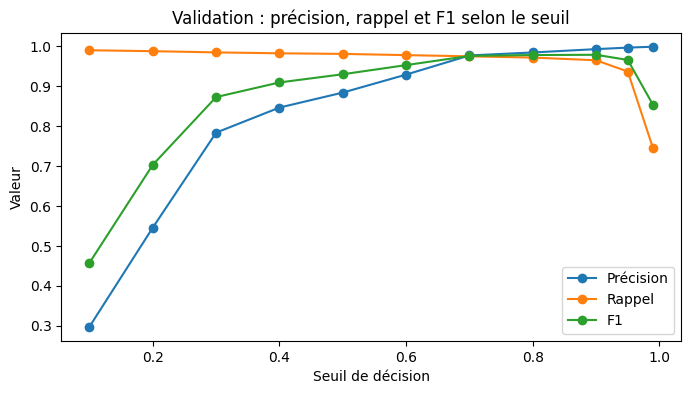

In [10]:
plt.figure(figsize=(8, 4))
plt.plot(seuils["seuil"], seuils["precision"], marker="o", label="Précision")
plt.plot(seuils["seuil"], seuils["rappel"], marker="o", label="Rappel")
plt.plot(seuils["seuil"], seuils["f1"], marker="o", label="F1")
plt.xlabel("Seuil de décision")        # axe X
plt.ylabel("Valeur")                   # axe Y
plt.title("Validation : précision, rappel et F1 selon le seuil")
plt.legend()
plt.show()

Axe X : seuil de décision ; axe Y : valeur de la métrique. La précision monte avec le seuil, le rappel reste stable jusqu'à 0,9 puis baisse : le F1 culmine à 0,9.

## 8. Sauvegarde du modèle et du seuil

In [11]:
meilleur_modele.write().overwrite().save(DATA + "/modeles/modele_fraude")

with open(DATA + "/modeles/seuil.txt", "w") as f:
    f.write(str(meilleur_seuil))

print("Modèle et seuil sauvegardés dans", DATA + "/modeles")

Modèle et seuil sauvegardés dans /opt/spark-data/modeles


In [12]:
spark.stop()